# Аналітика особистих витрат monobank

**Задача:** зрозуміти структуру моїх витрат за останні 6 місяців — на що, коли і як я витрачаю — і знайти патерни за допомогою ML.

**Дані:** особиста виписка, вивантажена через відкритий API monobank (`fetch_statement.py`).

**Інструменти:** Python, pandas, matplotlib, scikit-learn; код писався разом з AI (ChatGPT / Claude).

> 🔒 **Приватність:** у режимі `PUBLIC = True` ноутбук показує лише частки (%) та індекси, без реальних сум і назв магазинів — так його можна публікувати на GitHub.

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

PUBLIC = True   # False — показати реальні суми й магазини (тільки для себе!)

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 1. Завантаження даних

In [52]:
df = pd.read_csv("transactions.csv", parse_dates=["datetime"])
print(f"Транзакцій: {len(df)}, період: {df.datetime.min():%Y-%m-%d} — {df.datetime.max():%Y-%m-%d}")
df.dtypes

Транзакцій: 194, період: 2026-05-27 — 2026-11-21


datetime           datetime64[us]
description                   str
mcc                         int64
amount                    float64
operationAmount           float64
currencyCode                int64
cashbackAmount            float64
dtype: object

## 2. Категорії за MCC-кодом

MCC (Merchant Category Code) — 4-значний код типу продавця, який приходить разом із транзакцією. Групуємо коди в зрозумілі категорії.

In [53]:
MCC_GROUPS = {
    "Продукти":        [5411, 5412, 5422, 5441, 5451, 5462, 5499, 5331],
    "Кафе й ресторани": [5811, 5812, 5813, 5814],
    "Транспорт":       [4111, 4112, 4121, 4131, 4784, 4789, 7523],
    "Пальне":          [5541, 5542, 5983],
    "Аптеки й здоров'я": [5122, 5912, 8011, 8021, 8031, 8041, 8042, 8043, 8049, 8050, 8062, 8071, 8099],
    "Одяг і взуття":   [5611, 5621, 5631, 5641, 5651, 5655, 5661, 5691, 5699, 5948],
    "Краса":           [5977, 7230, 7297, 7298],
    "Електроніка":     [5045, 5732, 5734, 5735, 5946],
    "Підписки й digital": [4899, 5815, 5816, 5817, 5818, 7372],
    "Зв'язок":         [4812, 4814, 4816],
    "Розваги":         [7832, 7841, 7922, 7929, 7932, 7933, 7991, 7994, 7996, 7997, 7999, 5733],
    "Дім":             [5200, 5211, 5231, 5251, 5261, 5712, 5719, 5722],
    "Тварини":         [742, 5995],
    "Маркетплейси":    [5262],
    "Комунальні":      [4900],
    "Подарунки":       [5947],
    "Послуги":         [8999, 7299],
    "Готівка":         [6010, 6011],
    "Перекази":        [4829, 6012, 6051, 6536, 6537, 6538, 6540],
}
MCC_TO_CAT = {code: cat for cat, codes in MCC_GROUPS.items() for code in codes}

df["category"] = df["mcc"].map(MCC_TO_CAT).fillna("Інше")

# Витрати = від'ємні суми; перекази не вважаємо покупками
spend = df[(df.amount < 0) & (df.category != "Перекази")].copy()
spend["spent"] = -spend["amount"]
spend["month"] = spend.datetime.dt.to_period("M")
spend["weekday"] = spend.datetime.dt.dayofweek          # 0 = понеділок
spend["hour"] = spend.datetime.dt.hour

print(f"Покупок (без переказів): {len(spend)} з {len(df)}")
spend.category.value_counts()

Покупок (без переказів): 122 з 194


/var/folders/dj/wfnkb1cn54sdc7sxv0f7wdnm0000gn/T/ipykernel_27191/2952404388.py:30: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  spend["weekday"] = spend.datetime.dt.dayofweek          # 0 = понеділок


category
Продукти              35
Краса                 24
Одяг і взуття         15
Зв'язок               11
Кафе й ресторани       8
Підписки й digital     7
Розваги                5
Комунальні             5
Маркетплейси           4
Транспорт              4
Послуги                2
Подарунки              1
Електроніка            1
Name: count, dtype: int64

## 3. Ключові метрики

In [54]:
months = spend.month.nunique()
metrics = {
    "Кількість покупок": len(spend),
    "Покупок на місяць": round(len(spend) / months, 1),
    "Медіанний чек / середній чек": round(spend.spent.median() / spend.spent.mean(), 2),
    "Частка покупок у вихідні, %": round(spend.weekday.ge(5).mean() * 100, 1),
}
if not PUBLIC:
    metrics.update({
        "Всього витрачено, грн": round(spend.spent.sum()),
        "Середній чек, грн": round(spend.spent.mean()),
        "Медіанний чек, грн": round(spend.spent.median()),
        "Витрати на місяць, грн": round(spend.spent.sum() / months),
    })
pd.Series(metrics, name="значення").to_frame()

,значення
Кількість покупок,122.00
Покупок на місяць,17.40
Медіанний чек / середній чек,0.51
"Частка покупок у вихідні, %",29.50


## 4. На що я витрачаю: частка категорій

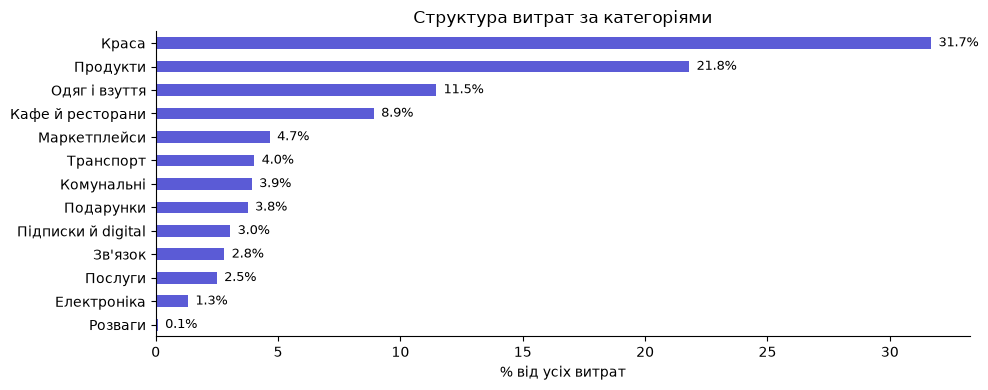

In [55]:
by_cat = (spend.groupby("category").spent.sum() / spend.spent.sum() * 100).sort_values()
ax = by_cat.plot.barh(color="#5b5bd6")
ax.set_xlabel("% від усіх витрат"); ax.set_ylabel("")
ax.set_title("Структура витрат за категоріями")
for i, v in enumerate(by_cat):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

## 5. Динаміка по місяцях (індекс: середній місяць = 100, лише повні місяці)

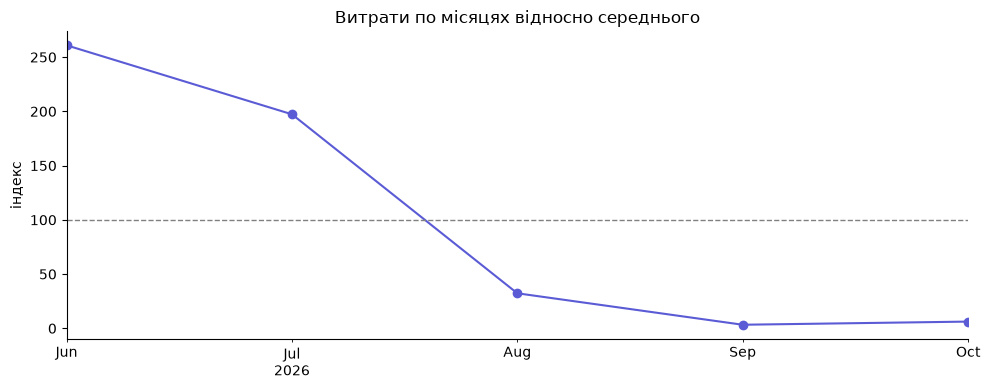

,індекс
month,
2026-06,260.9
2026-07,197.3
2026-08,32.3
2026-09,3.3
2026-10,6.2


In [56]:
# первый и последний месяцы выгрузки обычно неполные — не включаем их в динамику
first, last = spend.month.min(), spend.month.max()
full = spend[(spend.month > first) | (spend.datetime.min().day <= 3)]
full = full[(full.month < last) | (spend.datetime.max().day >= 28)]
monthly = full.groupby("month").spent.sum()
monthly_index = (monthly / monthly.mean() * 100).round(1)
ax = monthly_index.plot(marker="o", color="#5b5bd6")
ax.axhline(100, ls="--", color="grey", lw=1)
ax.set_ylabel("індекс"); ax.set_xlabel("")
ax.set_title("Витрати по місяцях відносно середнього")
plt.tight_layout(); plt.show()
monthly_index.to_frame("індекс")

## 6. Коли я витрачаю: дні тижня та години

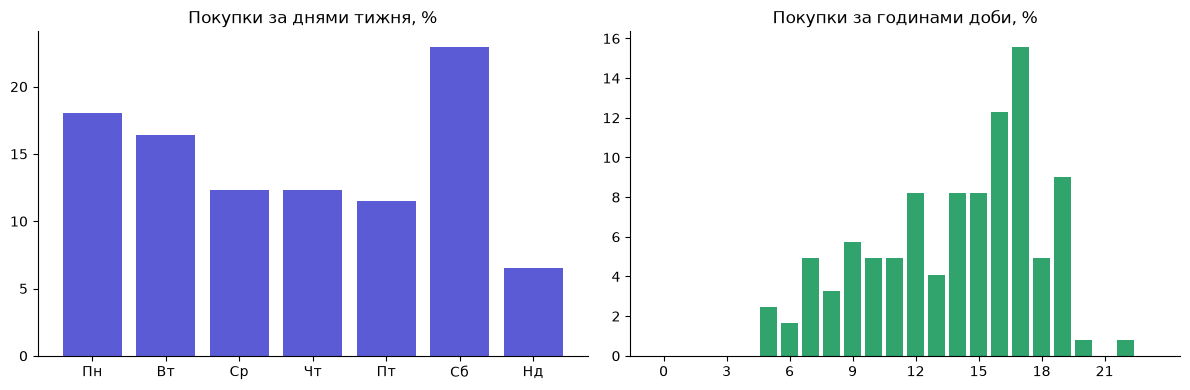

In [57]:
days = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Нд"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))

wd = spend.groupby("weekday").size().reindex(range(7), fill_value=0)
a1.bar(days, wd / wd.sum() * 100, color="#5b5bd6")
a1.set_title("Покупки за днями тижня, %")

hr = spend.groupby("hour").size().reindex(range(24), fill_value=0)
a2.bar(hr.index, hr / hr.sum() * 100, color="#30a46c")
a2.set_title("Покупки за годинами доби, %"); a2.set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.show()

## 7. Найчастіші місця покупок

In [58]:
top = spend.groupby("description").agg(покупок=("spent", "size"), частка_витрат=("spent", "sum"))
top["частка_витрат"] = (top["частка_витрат"] / spend.spent.sum() * 100).round(1)
top = top.sort_values("покупок", ascending=False).head(10)
if PUBLIC:
    # назви магазинів — особисті дані, у публічній версії ховаємо
    top.index = [f"Місце {i+1}" for i in range(len(top))]
top

,покупок,частка_витрат
Місце 1,22,16.9
Місце 2,21,17.8
Місце 3,8,1.5
Місце 4,6,1.6
Місце 5,5,0.4
Місце 6,5,0.1
Місце 7,4,1.1
Місце 8,4,4.0
Місце 9,4,1.0
Місце 10,4,1.1


## 8. ML: кластеризація покупок (KMeans)

**Ідея:** модель без підказок ділить покупки на групи за схожістю — розмір чека, час доби, будній/вихідний. Так видно «типи» моїх покупок.

- `log(сума)` — бо чеки дуже різні за розміром, логарифм вирівнює масштаб;
- години кодуємо через sin/cos, щоб 23:00 і 00:00 вважалися близькими;
- кількість кластерів обираємо за **silhouette score** (чим вище, тим чіткіше розділені групи).

In [59]:
X = pd.DataFrame({
    "log_amount": np.log1p(spend.spent),
    "hour_sin": np.sin(2 * np.pi * spend.hour / 24),
    "hour_cos": np.cos(2 * np.pi * spend.hour / 24),
    "weekend": spend.weekday.ge(5).astype(int),
})
X_scaled = StandardScaler().fit_transform(X)

scores = {}
for k in range(2, 5):   # 2–4 групи: більше на ~200 покупках важко інтерпретувати
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)
best_k = max(scores, key=scores.get)
print("Silhouette:", {k: round(s, 3) for k, s in scores.items()})
print("Обрано кластерів:", best_k)

spend["cluster"] = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit_predict(X_scaled)

Silhouette: {2: 0.263, 3: 0.312, 4: 0.35}
Обрано кластерів: 4


In [60]:
median_all = spend.spent.median()
profile = spend.groupby("cluster").agg(
    покупок=("spent", "size"),
    чек_відносно_медіани=("spent", lambda s: round(s.median() / median_all, 2)),
    типова_година=("hour", "median"),
    вихідні_pct=("weekday", lambda s: round(s.ge(5).mean() * 100)),
    топ_категорія=("category", lambda s: s.value_counts().index[0]),
)
profile["частка_витрат_pct"] = (spend.groupby("cluster").spent.sum() / spend.spent.sum() * 100).round(1)
profile

,покупок,чек_відносно_медіани,типова_година,вихідні_pct,топ_категорія,частка_витрат_pct
cluster,,,,,,
0,17,0.75,18.0,94,Продукти,6.1
1,51,1.37,16.0,0,Продукти,60.2
2,34,0.78,9.0,0,Зв'язок,16.2
3,20,1.68,12.0,100,Продукти,17.5


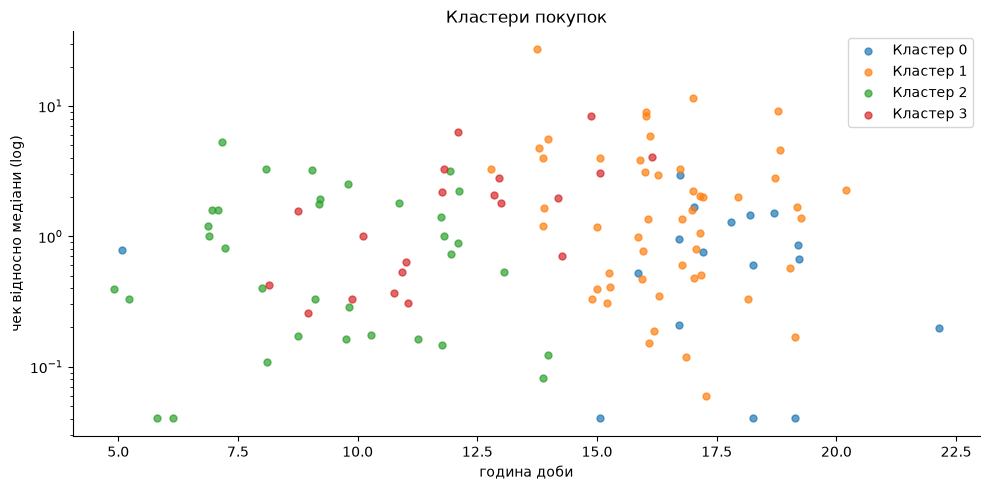

In [61]:
fig, ax = plt.subplots(figsize=(10, 5))
for c in sorted(spend.cluster.unique()):
    part = spend[spend.cluster == c]
    jitter = np.random.default_rng(c).uniform(-0.3, 0.3, len(part))
    ax.scatter(part.hour + jitter, part.spent / median_all, s=25, alpha=0.7, label=f"Кластер {c}")
ax.set_yscale("log")
ax.set_xlabel("година доби"); ax.set_ylabel("чек відносно медіани (log)")
ax.set_title("Кластери покупок"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Висновки

1. Найбільша категорія — **краса (~32%)**, разом із продуктами (~22%) це понад половину всіх витрат.
2. Витрати по цій картці різко впали з серпня (індекс з ~260 у червні до ~3–6 у вересні–жовтні): я переїхала до Польщі й почала користуватися місцевою карткою. Висновок: дані покривають лише один рахунок — для повної картини треба об'єднувати джерела.
3. Найактивніший день — **субота (23% покупок)**, найтихіший — неділя (~6%); пік за часом — **16–17 година**.
4. KMeans виділив 4 типи покупок; головний — покупки в будні близько 16:00 (60% витрат). Сильніше за все модель розділила будні й вихідні — наступний крок: додати категорію як ознаку.
5. Спочатку ~15% витрат потрапили в «Інше» — я розширила мапінг MCC-кодів (маркетплейси, комунальні, подарунки, послуги).

## 10. Експорт для дашборду (лише відсотки та індекси — без реальних сум)

In [62]:
summary = {
    "period": [str(spend.month.min()), str(spend.month.max())],
    "purchases": int(len(spend)),
    "categories_pct": by_cat.sort_values(ascending=False).round(1).to_dict(),
    "monthly_index": {str(k): float(v) for k, v in monthly_index.items()},
    "weekday_pct": dict(zip(days, (wd / wd.sum() * 100).round(1).tolist())),
    "hour_pct": {int(h): float(v) for h, v in (hr / hr.sum() * 100).round(1).items()},
    "clusters": profile.reset_index().to_dict(orient="records"),
}
import json
with open("summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)
print("summary.json збережено")

summary.json збережено


In [63]:
import os
os.makedirs("docs", exist_ok=True)
with open("docs/data.js", "w", encoding="utf-8") as f:
    f.write("window.SUMMARY = " + json.dumps(summary, ensure_ascii=False, default=str) + ";")
print("docs/data.js збережено")

docs/data.js збережено
